# Dependencia con la temperatura


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Path('images').mkdir(exist_ok=True)

G1 = 600.0
G2 = 500.0
RA = 10.0
RB = 9960.0
RC = 100800.0

df01 = 110961.0  # Hz, banda 0.1-100 kHz
df1 = 109961.0   # Hz, banda 1-100 kHz
kB_ref = 1.380649e-23  # J/K

FIT_TMIN = 197.46
FIT_TMAX = 253.62

In [ ]:
temperature_K = np.array([
    77.32, 90.0, 100.0, 110.0, 120.0, 130.0, 140.0, 150.0,
    160.0, 170.0, 180.0, 190.0, 200.0, 210.0, 220.0, 230.0,
    240.0, 250.0, 260.0, 270.0, 280.0, 290.0, 300.0, 310.0,
    320.0, 330.0, 340.0, 350.0, 360.0, 370.0, 380.0, 390.0, 400.0
])
voltage_mV = np.array([
    994.419, 967.032, 944.477, 921.305, 897.616, 873.417, 848.864,
    823.964, 798.691, 773.213, 747.485, 721.533, 695.363, 669.002,
    642.448, 615.748, 588.907, 561.837, 534.655, 507.311, 479.881,
    452.258, 424.465, 396.645, 368.731, 340.625, 312.542, 284.206,
    255.855, 227.428, 198.940, 170.463, 142.124
])

VT = np.array([910.0, 847.0, 801.0, 755.0, 702.0, 647.0, 600.0, 552.0])
T = np.interp(VT, voltage_mV[::-1], temperature_K[::-1])

pd.DataFrame({'V_T (mV)': VT, 'T (K)': T})

,V_T (mV),T (K)
0,910.0,114.772257
1,847.0,140.748594
2,801.0,159.086377
3,755.0,177.079058
4,702.0,197.463890
5,647.0,218.285757
6,600.0,235.867144
7,552.0,253.618939


In [ ]:
V01 = np.array([
    [2.4266666666666663, 4.15090909090909, 4.170833333333333],
    [4.007, 4.095, 4.061111111111111],
    [3.964, 4.00375, 4.0233333333333325],
    [4.14, 3.9925, 4.0874999999999995],
    [4.180000000000001, 4.053333333333333, 3.9775],
    [4.1325, 4.04375, 3.914444444444445],
    [3.9955555555555557, 4.028, 4.076666666666666],
    [4.314444444444444, 4.109090909090909, 4.042857142857143]
])
S01 = np.array([
    [0.07766803224186403, 0.010992108363775878, 0.029834349060074736],
    [0.008698658900466583, 0.01738599227173211, 0.004230985058813302],
    [0.0030550504633038928, 0.004977628523130773, 0.005270462766947319],
    [0.023080885440712004, 0.0036596252735569754, 0.0146079723830126],
    [0.0065465367070797935, 0.01452966314513559, 0.004909902530309837],
    [0.019977666101352914, 0.020953818267800274, 0.008012336167697745],
    [0.006260793149769237, 0.013232955494186108, 0.006666666666666612],
    [0.035555555555555556, 0.01371492521137901, 0.013577692789888785]
])

V1 = np.array([
    [0.9682142857142857, 3.3654545454545457, 1.9721428571428572],
    [2.015454545454545, 2.8737500000000002, 3.2411111111111115],
    [3.4466666666666668, 2.93375, 3.062727272727273],
    [3.556363636363636, 1.9899999999999995, 1.905833333333333],
    [1.8499999999999999, 1.9689999999999999, 1.8036363636363637],
    [1.8059999999999998, 1.9116666666666664, 1.9924999999999997],
    [1.986, 1.9522222222222223, 2.0413333333333328],
    [1.8399999999999999, 2.192, 2.1920000000000006]
])
S1 = np.array([
    [0.003494388863904835, 0.036813130966684274, 0.011250327049144655],
    [0.02257768956549147, 0.00864735715200234, 0.0071578326259583895],
    [0.014319584667528069, 0.017922202909878504, 0.03230791935257611],
    [0.015092004341416103, 0.0057735026918962415, 0.009491490074713445],
    [0.019863168290719733, 0.0093630479367921, 0.007540524128482814],
    [0.007916228058025285, 0.007031674369909669, 0.016242713984299474],
    [0.005099019513592789, 0.003239417719358503, 0.02366163595090196],
    [0.021984843263788186, 0.011234866364235157, 0.005120763831912426]
])

In [ ]:
factor = 10.0 / (G1 * G2)**2

def corrected_signals(V, S):
    Vtot = factor * V
    sVtot = factor * S

    Y_B = Vtot[:, 1] - Vtot[:, 0]
    sY_B = np.sqrt(sVtot[:, 1]**2 + sVtot[:, 0]**2)

    Y_C = Vtot[:, 2] - Vtot[:, 0]
    sY_C = np.sqrt(sVtot[:, 2]**2 + sVtot[:, 0]**2)

    return Y_B, sY_B, Y_C, sY_C

Y01_B, SY01_B, Y01_C, SY01_C = corrected_signals(V01, S01)
Y1_B, SY1_B, Y1_C, SY1_C = corrected_signals(V1, S1)

In [ ]:
def weighted_linear_fit(x, y, sy, Tmin=FIT_TMIN, Tmax=FIT_TMAX,
                        resistance=None, bandwidth=None):

    mask = (x >= Tmin) & (x <= Tmax)
    xx = np.asarray(x[mask], float)
    yy = np.asarray(y[mask], float)
    ss = np.asarray(sy[mask], float)

    X = np.column_stack([xx, np.ones_like(xx)])
    w = 1.0 / ss**2
    XT_W = X.T * w
    cov = np.linalg.inv(XT_W @ X)
    beta = cov @ (XT_W @ yy)
    m, b = beta
    sm, sb = np.sqrt(np.diag(cov))

    yfit = X @ beta
    residuals = (yy - yfit) / ss

    chi2 = np.sum(residuals**2)
    nu = len(xx) - 2

    ybar_w = np.sum(w * yy) / np.sum(w)
    ss_res = np.sum(w * (yy - yfit)**2)
    ss_tot = np.sum(w * (yy - ybar_w)**2)
    R2 = 1.0 - ss_res / ss_tot

    result = {
        'mask': mask,
        'x': xx,
        'y': yy,
        'sy': ss,
        'm': m,
        'sm': sm,
        'b': b,
        'sb': sb,
        'R2': R2,
        'chi2': chi2,
        'nu': nu,
        'residuals': residuals,
        'cov': cov,
    }

    if resistance is not None and bandwidth is not None:
        kB = m / (4.0 * resistance * bandwidth)
        skB = sm / (4.0 * resistance * bandwidth)
        result.update({
            'kB': kB,
            'skB': skB,
        })
    return result

fit01_B = weighted_linear_fit(T, Y01_B, SY01_B, resistance=RB, bandwidth=df01)
fit01_C = weighted_linear_fit(T, Y01_C, SY01_C, resistance=RC, bandwidth=df01)
fit1_B = weighted_linear_fit(T, Y1_B, SY1_B, resistance=RB, bandwidth=df1)
fit1_C = weighted_linear_fit(T, Y1_C, SY1_C, resistance=RC, bandwidth=df1)


In [ ]:
def one_sig_parenthetical(value, uncertainty, scale=1.0):
    """Notación v(u) con una sola cifra significativa en la incertidumbre."""
    v = float(value) / scale
    s = abs(float(uncertainty) / scale)
    if not np.isfinite(s) or s == 0:
        return f"{v:g}"

    order = int(np.floor(np.log10(s)))
    s1 = round(s, -order)
    
    order = int(np.floor(np.log10(s1))) if s1 != 0 else order
    decimals = max(0, -order)
    v1 = round(v, decimals)
    s1 = round(s, decimals)
    digits = int(round(s1 * (10**decimals)))
    return f"{v1:.{decimals}f}({digits})"


def fit_row(band, label, fit):
    return {
        'Banda (kHz)': band,
        'R': label,
        'm (1e-13 V^2/K)': fit['m']/1e-13,
        'sigma_m (1e-13 V^2/K)': fit['sm']/1e-13,
        'm (notacion)': one_sig_parenthetical(fit['m'], fit['sm'], 1e-13),
        'b (1e-11 V^2)': fit['b']/1e-11,
        'sigma_b (1e-11 V^2)': fit['sb']/1e-11,
        'b (notacion)': one_sig_parenthetical(fit['b'], fit['sb'], 1e-11),
        'kB (1e-23 J/K)': fit['kB']/1e-23,
        'sigma_kB (1e-23 J/K)': fit['skB']/1e-23,
        'kB (notacion)': one_sig_parenthetical(fit['kB'], fit['skB'], 1e-23),
        'R^2': fit['R2'],
        'chi2': fit['chi2'],
        'nu': fit['nu'],
    }

results = pd.DataFrame([
    fit_row('0.1-100', 'R_B', fit01_B),
    fit_row('0.1-100', 'R_C', fit01_C),
    fit_row('1-100', 'R_B', fit1_B),
    fit_row('1-100', 'R_C', fit1_C),
])
results.to_csv('resultados_ajustes_temperatura.csv', index=False)
results


,Banda (kHz),R,m (1e-13 V^2/K),sigma_m (1e-13 V^2/K),m (notacion),b (1e-11 V^2),sigma_b (1e-11 V^2),b (notacion),kB (1e-23 J/K),sigma_kB (1e-23 J/K),kB (notacion),R^2,chi2,nu
0,0.1-100,R_B,2.651900,0.558893,2.7(6),-6.480516,1.237744,-6(1),5.998842,1.264267,6(1),0.309272,50.283252,2
1,0.1-100,R_C,6.811429,0.337542,6.8(3),-15.706952,0.730985,-15.7(7),1.522465,0.075446,1.52(8),0.681908,189.953528,2
2,1-100,R_B,-2.417210,0.484524,-2.4(5),5.809676,1.119119,6(1),-5.517678,1.106006,-6(1),0.071970,320.930033,2
3,1-100,R_C,6.366111,0.583866,6.4(6),-12.718066,1.314487,-13(1),1.435870,0.131690,1.4(1),0.646102,65.117593,2


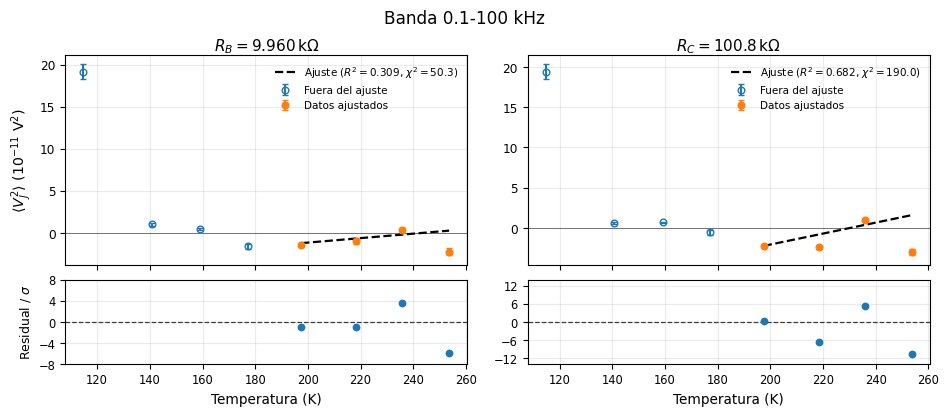

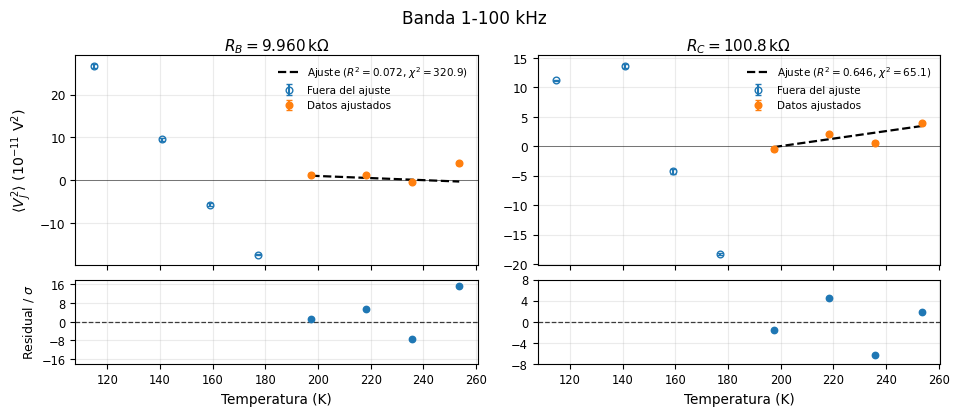

In [ ]:
from matplotlib.ticker import MaxNLocator


def make_band_figure(T, series, errors, fits, band_text, filename_base):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(9.4, 4.35),
        sharex='col',
        gridspec_kw={'height_ratios': [2.5, 1.0]}
    )
    titles = [r'$R_B=9.960\,\mathrm{k}\Omega$', r'$R_C=100.8\,\mathrm{k}\Omega$']

    for col, (y, sy, fit) in enumerate(zip(series, errors, fits)):
        ax = axes[0, col]
        axr = axes[1, col]
        mask = fit['mask']

        ax.errorbar(T[~mask], y[~mask]/1e-11, yerr=sy[~mask]/1e-11,
                    fmt='o', mfc='none', capsize=2.5, markersize=4.8,
                    label='Fuera del ajuste')
        ax.errorbar(T[mask], y[mask]/1e-11, yerr=sy[mask]/1e-11,
                    fmt='o', capsize=2.5, markersize=4.8,
                    label='Datos ajustados')

        xfit = np.linspace(T[mask].min(), T[mask].max(), 200)
        yfit = fit['m']*xfit + fit['b']
        ax.plot(
            xfit, yfit/1e-11, '--', color='black', linewidth=1.6,
            label=fr"Ajuste ($R^2={fit['R2']:.3f}$, $\chi^2={fit['chi2']:.1f}$)"
        )
        ax.axhline(0, color='black', linewidth=0.65, alpha=0.55)
        ax.set_title(titles[col], fontsize=11, pad=1.5)
        ax.grid(alpha=0.25)
        ax.tick_params(labelsize=8.7)
        ax.legend(frameon=False, fontsize=7.5, loc='best')

        axr.axhline(0, color='black', linestyle='--', linewidth=0.9, alpha=0.75)
        axr.plot(T[mask], fit['residuals'], 'o', markersize=4.6)
        max_abs = float(np.max(np.abs(fit['residuals'])))
        lim = max(2.0, np.ceil((1.15 * max_abs) / 2.0) * 2.0)
        axr.set_ylim(-lim, lim)
        axr.yaxis.set_major_locator(MaxNLocator(nbins=5))
        axr.set_xlabel('Temperatura (K)', fontsize=9.8)
        axr.grid(alpha=0.25)
        axr.tick_params(labelsize=8.3)

    axes[0, 0].set_ylabel(r'$\langle V_J^2\rangle$ ($10^{-11}$ V$^2$)', fontsize=10.2)
    axes[1, 0].set_ylabel(r'Residual / $\sigma$', fontsize=9.0)
    fig.suptitle(f'Banda {band_text}', fontsize=12.2, y=0.945)
    fig.subplots_adjust(left=0.075, right=0.995, bottom=0.13, top=0.84,
                        wspace=0.15, hspace=0.10)

    fig.savefig(f'images/{filename_base}.pdf', bbox_inches='tight')
    fig.savefig(f'images/{filename_base}.png', dpi=300, bbox_inches='tight')
    plt.show()

make_band_figure(
    T,
    [Y01_B, Y01_C],
    [SY01_B, SY01_C],
    [fit01_B, fit01_C],
    '0.1-100 kHz',
    'fig_01_100_grid'
)

make_band_figure(
    T,
    [Y1_B, Y1_C],
    [SY1_B, SY1_C],
    [fit1_B, fit1_C],
    '1-100 kHz',
    'fig_1_100_grid'
)
